
# Week 3 – Python & Data Wrangling

## Introduction

The objective of this task is to perform data cleaning and data wrangling using Python and Pandas.

The dataset contains workout information such as Duration, Date, Pulse, Maxpulse, and Calories.

The task includes handling missing values, removing duplicates, filtering rows, creating new columns, and visualizing the data using Matplotlib and Seaborn.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv")

df.head()


,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0


In [2]:

# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check data types and non-null values
print("\nDataset Information:")
df.info()

# Get statistical summary
print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (32, 5)

Column Names:
Index(['Duration', 'Date', 'Pulse', 'Maxpulse', 'Calories'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB

Statistical Summary:


,Duration,Pulse,Maxpulse,Calories
count,32.000000,32.000000,32.000000,30.000000
mean,68.437500,103.500000,128.500000,304.680000
std,70.039591,7.832933,12.998759,66.003779
min,30.000000,90.000000,101.000000,195.100000
25%,60.000000,100.000000,120.000000,250.700000
50%,60.000000,102.500000,127.500000,291.200000
75%,60.000000,106.500000,132.250000,343.975000
max,450.000000,130.000000,175.000000,479.000000



## Data Cleaning

- Identified missing values in the dataset.
- Filled missing Calories values using the median.
- Removed records with missing Date values.
- Removed duplicate records.
- Converted the Date column into a proper datetime format.


In [3]:

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

Total Missing Values:
3

Duplicate Rows:
1


In [4]:

# Create a copy so the original data remains unchanged
df_cleaned = df.copy()

print("Original Dataset Shape:", df_cleaned.shape)


Original Dataset Shape: (32, 5)


In [5]:

# Fill missing Calories values with the median
calories_median = df_cleaned['Calories'].median()

df_cleaned['Calories'] = df_cleaned['Calories'].fillna(calories_median)

print("Missing Calories after cleaning:")
print(df_cleaned['Calories'].isnull().sum())


Missing Calories after cleaning:
0


In [6]:

# Remove rows where Date is missing
df_cleaned = df_cleaned.dropna(subset=['Date'])

print("Missing Date values:")
print(df_cleaned['Date'].isnull().sum())


Missing Date values:
0


In [7]:

# Remove duplicate records
df_cleaned = df_cleaned.drop_duplicates()

print("Duplicate rows after cleaning:", df_cleaned.duplicated().sum())
print("Cleaned Dataset Shape:", df_cleaned.shape)


Duplicate rows after cleaning: 0
Cleaned Dataset Shape: (30, 5)


In [8]:

# Remove extra quotation marks and spaces from dates
df_cleaned['Date'] = df_cleaned['Date'].astype(str).str.strip("' ")

# Convert Date column into proper datetime format
df_cleaned['Date'] = pd.to_datetime(
    df_cleaned['Date'].str.replace('/', '-', regex=False),
    format='mixed',
    errors='coerce'
)

# Check the cleaned dates
print(df_cleaned['Date'].head(10))

# Check the data type
print("\nDate column data type:")
print(df_cleaned['Date'].dtype)

# Check for invalid dates
print("\nInvalid dates:", df_cleaned['Date'].isnull().sum())


0   2020-12-01
1   2020-12-02
2   2020-12-03
3   2020-12-04
4   2020-12-05
5   2020-12-06
6   2020-12-07
7   2020-12-08
8   2020-12-09
9   2020-12-10
Name: Date, dtype: datetime64[ns]

Date column data type:
datetime64[ns]

Invalid dates: 0


In [9]:

# Find records where Duration is greater than 120
unusual_records = df_cleaned[df_cleaned['Duration'] > 120]

display(unusual_records)


,Duration,Date,Pulse,Maxpulse,Calories
7,450,2020-12-08,104,134,253.3



## Data Filtering and Feature Creation

Filtered records based on Duration and Calories.

Created two new columns:

1. Calories_per_Minute – Calculates calories burned per minute.
2. Duration_Category – Classifies workout duration into Short, Medium, and Long categories.


In [10]:

# Filter records based on conditions
df_filtered = df_cleaned[
    (df_cleaned['Duration'] >= 30) &
    (df_cleaned['Calories'] > 0)
]

# Display filtered records
display(df_filtered.head(10))

print("Original cleaned rows:", len(df_cleaned))
print("Filtered rows:", len(df_filtered))


,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
2,60,2020-12-03,103,135,340.0
3,45,2020-12-04,109,175,282.4
4,45,2020-12-05,117,148,406.0
5,60,2020-12-06,102,127,300.0
6,60,2020-12-07,110,136,374.0
7,450,2020-12-08,104,134,253.3
8,30,2020-12-09,109,133,195.1
9,60,2020-12-10,98,124,269.0


Original cleaned rows: 30
Filtered rows: 30


In [11]:

# Calculate calories burned per minute
df_filtered['Calories_per_Minute'] = (
    df_filtered['Calories'] / df_filtered['Duration']
)

display(df_filtered.head())


,Duration,Date,Pulse,Maxpulse,Calories,Calories_per_Minute
0,60,2020-12-01,110,130,409.1,6.818333
1,60,2020-12-02,117,145,479.0,7.983333
2,60,2020-12-03,103,135,340.0,5.666667
3,45,2020-12-04,109,175,282.4,6.275556
4,45,2020-12-05,117,148,406.0,9.022222


In [12]:

# Categorize workout duration
df_filtered['Duration_Category'] = np.where(
    df_filtered['Duration'] <= 30, 'Short',
    np.where(df_filtered['Duration'] <= 60, 'Medium', 'Long')
)

display(df_filtered.head(10))


,Duration,Date,Pulse,Maxpulse,Calories,Calories_per_Minute,Duration_Category
0,60,2020-12-01,110,130,409.1,6.818333,Medium
1,60,2020-12-02,117,145,479.0,7.983333,Medium
2,60,2020-12-03,103,135,340.0,5.666667,Medium
3,45,2020-12-04,109,175,282.4,6.275556,Medium
4,45,2020-12-05,117,148,406.0,9.022222,Medium
5,60,2020-12-06,102,127,300.0,5.000000,Medium
6,60,2020-12-07,110,136,374.0,6.233333,Medium
7,450,2020-12-08,104,134,253.3,0.562889,Long
8,30,2020-12-09,109,133,195.1,6.503333,Short
9,60,2020-12-10,98,124,269.0,4.483333,Medium



## Data Visualization

Created visualizations using Matplotlib and Seaborn to understand the relationship between workout duration and calories burned.

- Bar chart: Average calories burned by duration category.
- Scatter plot: Relationship between duration and calories burned.


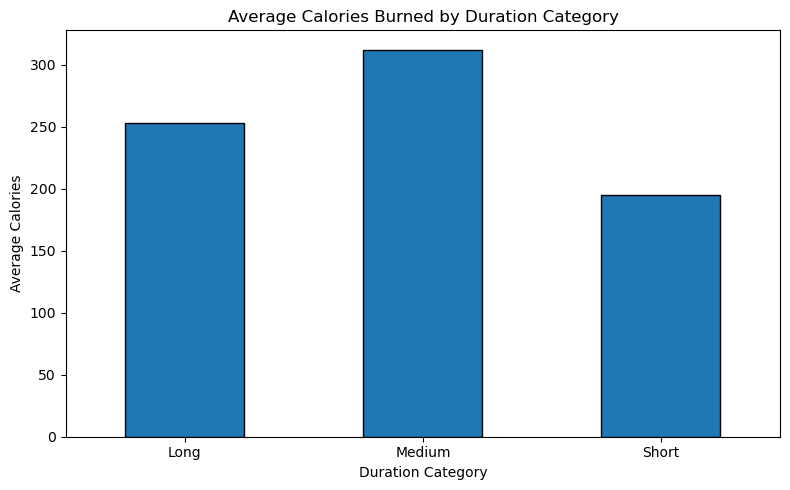

In [13]:

# Average calories by duration category
avg_calories = df_filtered.groupby(
    'Duration_Category'
)['Calories'].mean()

plt.figure(figsize=(8, 5))
avg_calories.plot(kind='bar', edgecolor='black')

plt.title('Average Calories Burned by Duration Category')
plt.xlabel('Duration Category')
plt.ylabel('Average Calories')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


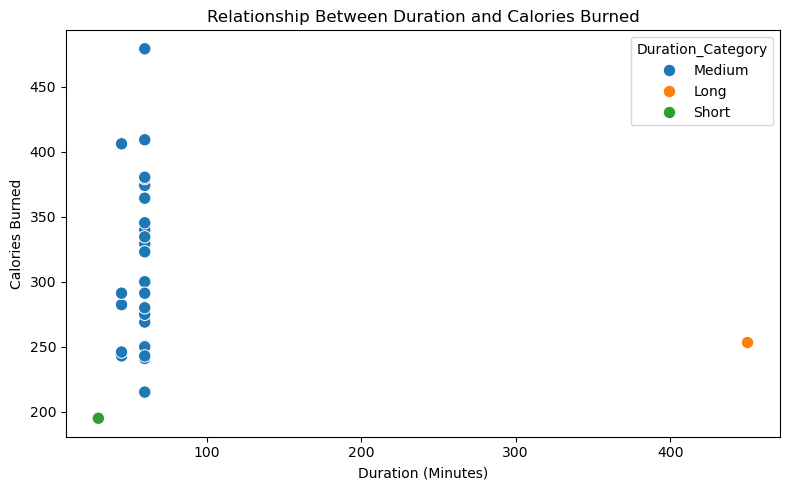

In [14]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_filtered,
    x='Duration',
    y='Calories',
    hue='Duration_Category',
    s=80
)

plt.title('Relationship Between Duration and Calories Burned')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Calories Burned')
plt.tight_layout()
plt.show()


In [15]:

print("Final Dataset Shape:", df_filtered.shape)

print("\nMissing Values:")
print(df_filtered.isnull().sum())

print("\nDuplicate Rows:")
print(df_filtered.duplicated().sum())

print("\nFinal Dataset:")
display(df_filtered.head(10))


Final Dataset Shape: (30, 7)

Missing Values:
Duration               0
Date                   0
Pulse                  0
Maxpulse               0
Calories               0
Calories_per_Minute    0
Duration_Category      0
dtype: int64

Duplicate Rows:
0

Final Dataset:


,Duration,Date,Pulse,Maxpulse,Calories,Calories_per_Minute,Duration_Category
0,60,2020-12-01,110,130,409.1,6.818333,Medium
1,60,2020-12-02,117,145,479.0,7.983333,Medium
2,60,2020-12-03,103,135,340.0,5.666667,Medium
3,45,2020-12-04,109,175,282.4,6.275556,Medium
4,45,2020-12-05,117,148,406.0,9.022222,Medium
5,60,2020-12-06,102,127,300.0,5.000000,Medium
6,60,2020-12-07,110,136,374.0,6.233333,Medium
7,450,2020-12-08,104,134,253.3,0.562889,Long
8,30,2020-12-09,109,133,195.1,6.503333,Short
9,60,2020-12-10,98,124,269.0,4.483333,Medium



# Conclusion

In this internship task, I performed data cleaning and data wrangling using Python, Pandas, NumPy, Matplotlib, and Seaborn.

I handled missing values, removed duplicate records, cleaned date formats, filtered data, and created new columns for further analysis.

I also created visualizations to understand the relationship between workout duration and calories burned.

This task helped me improve my practical understanding of Python data analysis and data wrangling techniques.
